In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization Settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Define Dataset Columns

columns = [
    'age', 'workclass', 'fnlwgt', 'education',
    'education_num', 'marital_status', 'occupation',
    'relationship', 'race', 'sex', 'capital_gain',
    'capital_loss', 'hours_per_week',
    'native_country', 'income'
]

# Load Training Dataset
train_df = pd.read_csv(
    'adult.data',
    names=columns,
    sep=',',
    skipinitialspace=True
)

# Load Testing Dataset
test_df = pd.read_csv(
    'adult.test',
    names=columns,
    sep=',',
    skipinitialspace=True,
    skiprows=1
)

# Remove the final period from test labels
test_df['income'] = test_df['income'].str.strip().str.replace(
    '.', '', regex=False
)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

display(train_df.head())

Training Dataset Shape: (32561, 15)
Testing Dataset Shape: (16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("========== DATASET INFORMATION ==========")

print("\nDataset Shape:")
print(train_df.shape)

print("\nData Types:")
print(train_df.dtypes)

print("\nMissing Values:")
print(train_df.replace('?', np.nan).isnull().sum())

print("\nIncome Distribution:")
print(train_df['income'].value_counts())

print("\nIncome Distribution Percentage:")
print(
    train_df['income']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

========== DATASET INFORMATION ==========

Dataset Shape:
(32561, 15)

Data Types:
age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object

Missing Values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Income Distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Income Distribution Percentage:
income
<=50K    75.92
>50K     24.0

In [4]:
# Replace '?' with NaN
train_df.replace('?', np.nan, inplace=True)
test_df.replace('?', np.nan, inplace=True)

# Check missing values
print("Training Missing Values:")
print(train_df.isnull().sum())

print("\nTesting Missing Values:")
print(test_df.isnull().sum())

Training Missing Values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Testing Missing Values:
age                 0
workclass         963
fnlwgt              0
education           0
education_num       0
marital_status      0
occupation        966
relationship        0
race                0
sex                 0
capital_gain        0
capital_loss        0
hours_per_week      0
native_country    274
income              0
dtype: int64


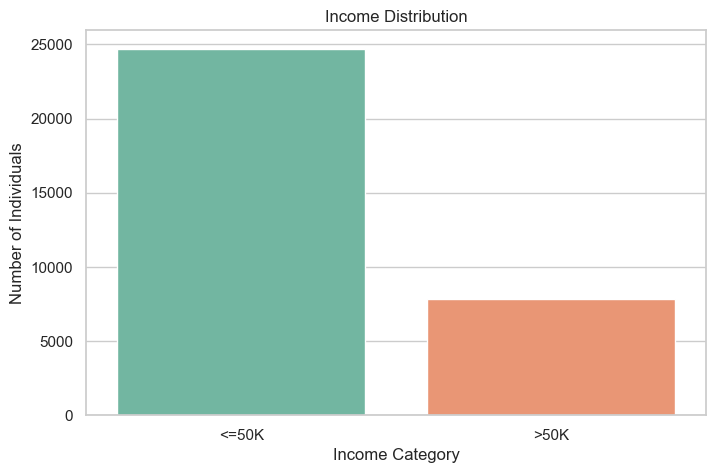

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x='income',
    hue='income',
    palette='Set2',
    legend=False
)

plt.title('Income Distribution')
plt.xlabel('Income Category')
plt.ylabel('Number of Individuals')
plt.show()

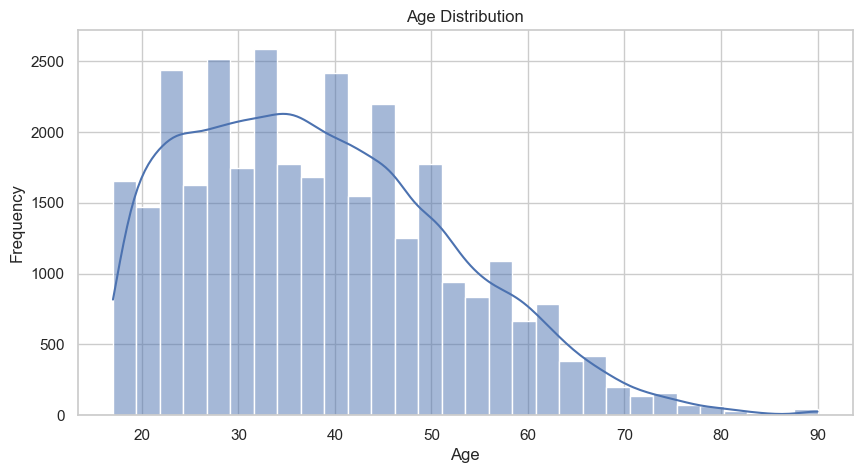

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x='age',
    bins=30,
    kde=True
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

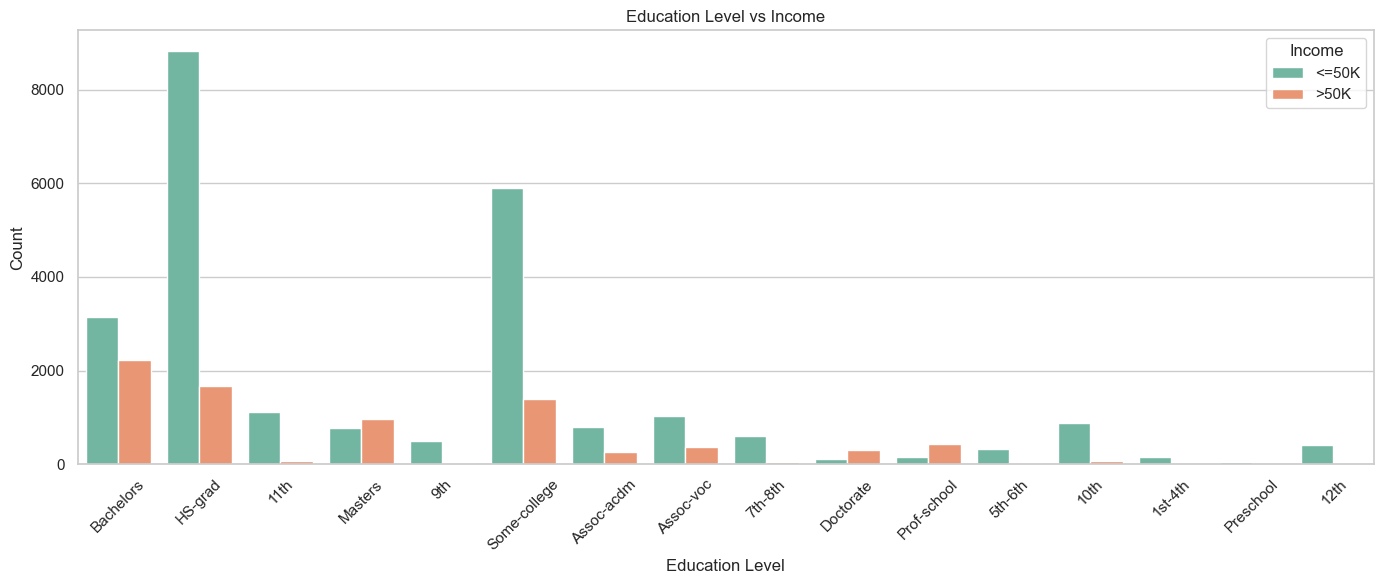

In [7]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=train_df,
    x='education',
    hue='income',
    palette='Set2'
)

plt.title('Education Level vs Income')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Income')

plt.tight_layout()
plt.show()

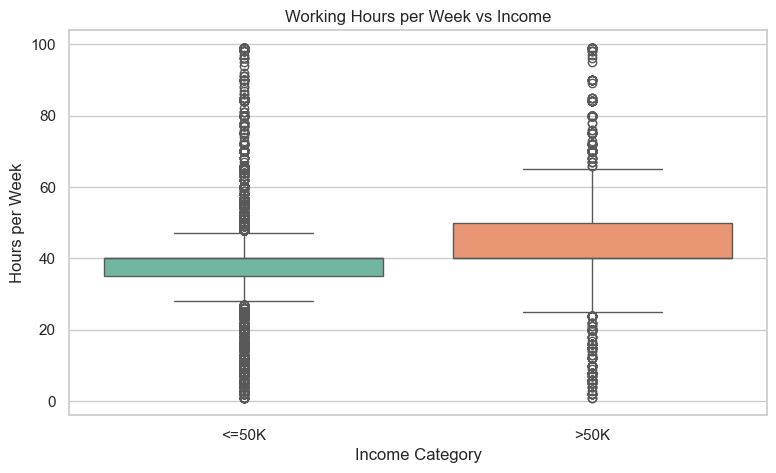

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_df,
    x='income',
    y='hours_per_week',
    hue='income',
    palette='Set2',
    legend=False
)

plt.title('Working Hours per Week vs Income')
plt.xlabel('Income Category')
plt.ylabel('Hours per Week')

plt.show()

In [9]:
# Separate Features and Target

X_train = train_df.drop('income', axis=1)
y_train = train_df['income']

X_test = test_df.drop('income', axis=1)
y_test = test_df['income']

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTarget Classes:")
print(y_train.unique())

Training Features: (32561, 14)
Testing Features: (16281, 14)

Target Classes:
['<=50K' '>50K']


In [10]:
# Identify Numerical Features
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify Categorical Features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Number of Numerical Features: 6
Number of Categorical Features: 8


In [11]:
# Numerical Pipeline
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Pipeline
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine Both Pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [12]:
# Fit on Training Data Only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform Testing Data
X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:")
print(X_train_processed.shape)

print("\nTesting Data After Preprocessing:")
print(X_test_processed.shape)

Training Data After Preprocessing:
(32561, 105)

Testing Data After Preprocessing:
(16281, 105)


In [13]:
# Convert Income Labels into Binary Values

y_train = y_train.str.strip().map({
    '<=50K': 0,
    '>50K': 1
})

y_test = y_test.str.strip().map({
    '<=50K': 0,
    '>50K': 1
})

print("Training Target Classes:")
print(y_train.value_counts())

print("\nTesting Target Classes:")
print(y_test.value_counts())

assert y_train.notna().all()
assert y_test.notna().all()

print("\nTarget Encoding Completed Successfully!")

Training Target Classes:
income
0    24720
1     7841
Name: count, dtype: int64

Testing Target Classes:
income
0    12435
1     3846
Name: count, dtype: int64

Target Encoding Completed Successfully!


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        early_stopping=True,
        random_state=42
    )
}

print("Models are ready!")

Models are ready!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from scipy import sparse

# Convert data to dense format for MLP
X_train_mlp = (
    X_train_processed.toarray()
    if sparse.issparse(X_train_processed)
    else X_train_processed
)

X_test_mlp = (
    X_test_processed.toarray()
    if sparse.issparse(X_test_processed)
    else X_test_processed
)

results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    if name == "MLP Neural Network":
        model.fit(X_train_mlp, y_train)
        y_pred = model.predict(X_test_mlp)
    else:
        model.fit(X_train_processed, y_train)
        y_pred = model.predict(X_test_processed)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

print("All models have been trained!")

Training Logistic Regression...
Training Random Forest...
Training MLP Neural Network...
All models have been trained!


In [16]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,MLP Neural Network,0.853326,0.718525,0.623245,0.667502
1,Random Forest,0.851545,0.717769,0.612324,0.660867
2,Logistic Regression,0.850685,0.728152,0.587103,0.650065


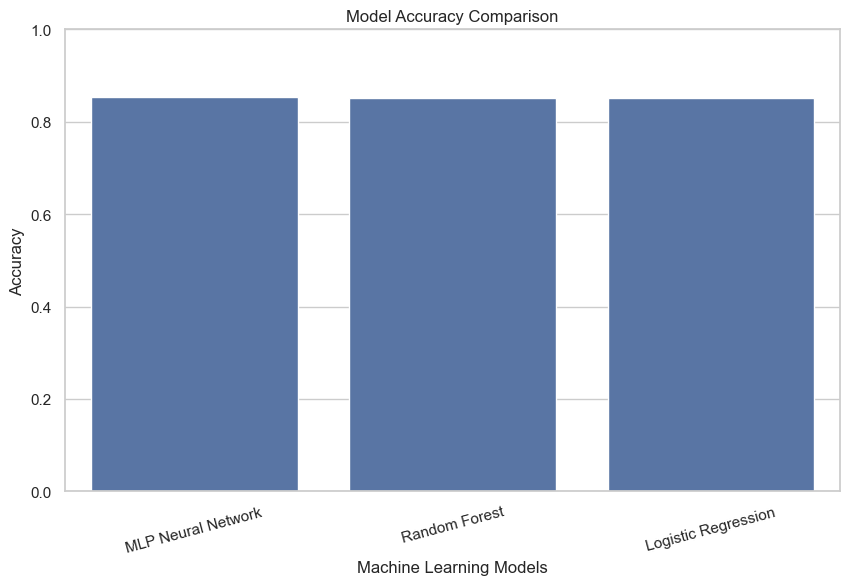

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

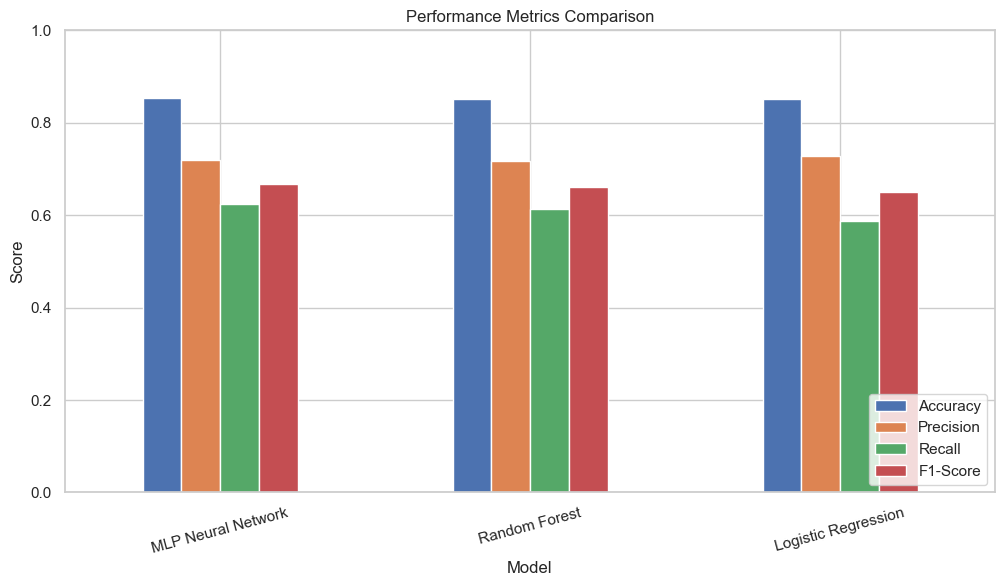

In [18]:
metrics_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

metrics_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.show()

In [19]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1-Score:", results_df.iloc[0]["F1-Score"])

Best Model: MLP Neural Network
Best F1-Score: 0.6675020885547202


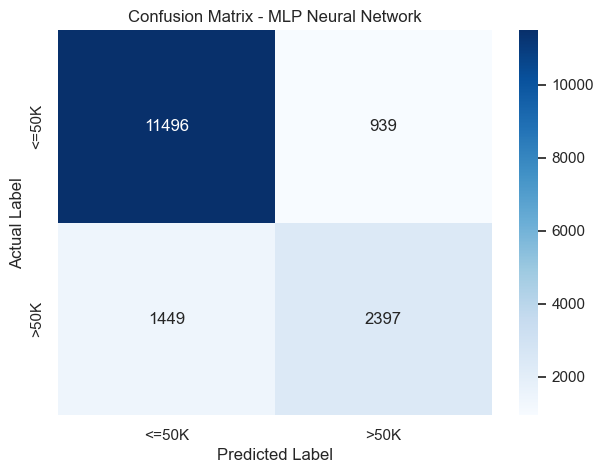

              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.91     12435
        >50K       0.72      0.62      0.67      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.79     16281
weighted avg       0.85      0.85      0.85     16281



In [20]:
from sklearn.metrics import confusion_matrix, classification_report

if best_model_name == "MLP Neural Network":
    y_pred_best = best_model.predict(X_test_mlp)
else:
    y_pred_best = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print(classification_report(
    y_test,
    y_pred_best,
    target_names=["<=50K", ">50K"]
))

In [21]:
# Get the trained Random Forest model
rf_model = trained_models["Random Forest"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
1,num__fnlwgt,0.166448
0,num__age,0.152106
3,num__capital_gain,0.097045
5,num__hours_per_week,0.084744
2,num__education_num,0.062213
32,cat__marital_status_Married-civ-spouse,0.055100
51,cat__relationship_Husband,0.046767
4,num__capital_loss,0.031352
34,cat__marital_status_Never-married,0.025296
40,cat__occupation_Exec-managerial,0.017409


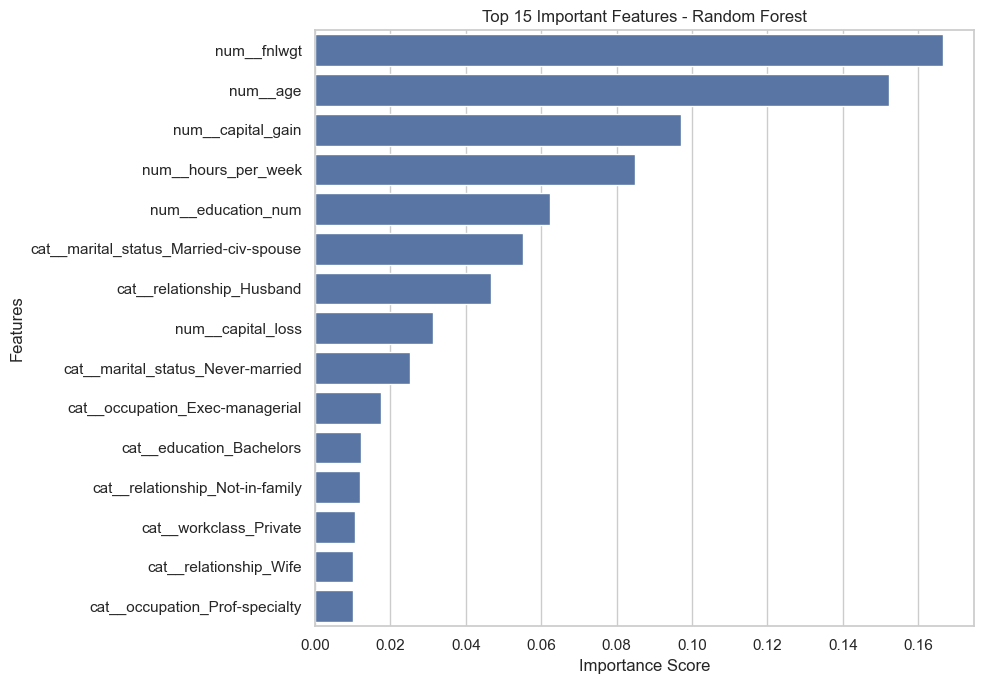

In [22]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [23]:
import joblib

joblib.dump(best_model, "best_income_model.pkl")

joblib.dump(preprocessor, "income_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [24]:
loaded_model = joblib.load("best_income_model.pkl")
loaded_preprocessor = joblib.load("income_preprocessor.pkl")

print("Model loaded successfully!")
print("Model:", best_model_name)

Model loaded successfully!
Model: MLP Neural Network
